In [1]:
import pandas as pd
import numpy as np

In [2]:
from sklearn import datasets

cali = datasets.fetch_california_housing()

In [3]:
print (cali.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [4]:
df = pd.DataFrame(cali.data, columns=cali.feature_names)

In [5]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [6]:
df['home_value'] = cali.target

In [7]:
df.isnull( ).sum( )

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
home_value    0
dtype: int64

In [8]:
x = df.drop('home_value', axis=1)

In [9]:
y = df['home_value']

In [10]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=5)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(16512, 8)
(4128, 8)
(16512,)
(4128,)


In [11]:
#train the models with the training and test sets 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
lin_model = LinearRegression()
lin_model.fit (x_train, y_train)

LinearRegression()

In [12]:
#model evaluation for training set

In [13]:
y_train_predict = lin_model.predict(x_train)

In [14]:
rmse=(np.sqrt(mean_squared_error(y_train, y_train_predict)))

In [15]:
r2=r2_score(y_train, y_train_predict)

In [16]:
print("the model performance for training set")

the model performance for training set


In [17]:
print("-------------------------")

-------------------------


In [18]:
print('RMSE is{}'.format(rmse))

RMSE is0.7221082719887488


In [19]:
print('R2 sccore is{}'.format(r2))

R2 sccore is0.6047922425924859


In [20]:
print("\n")

In [21]:
#evaluation for testing set

In [22]:
y_test_predict = lin_model.predict(x_test)

In [23]:
rmse=(np.sqrt(mean_squared_error(y_test, y_test_predict)))

In [24]:
r2=r2_score(y_test, y_test_predict)

In [25]:
print("the model performance for test set")

the model performance for test set


In [26]:
print('-------------------')

-------------------


In [27]:
print('RMSE is{}'.format(rmse))

RMSE is0.7323542382277796


In [28]:
print('R2 score{}'.format(r2))

R2 score0.6112568432827635


In [29]:
lin_model.intercept_

np.float64(-36.895542973980085)

In [30]:
lin_model.coef_

array([ 4.38384807e-01,  9.17273492e-03, -1.11793600e-01,  6.79331516e-01,
       -3.04158117e-06, -4.12179113e-03, -4.19560244e-01, -4.33473567e-01])

In [31]:
lin_model.feature_names_in_

array(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population',
       'AveOccup', 'Latitude', 'Longitude'], dtype=object)

In [32]:
import pandas as pd
import numpy as np
from sklearn import preprocessing
import matplotlib.pyplot as plt
plt.rc("font", size=14)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import seaborn as sns
sns.set(style="white")
sns.set(style="whitegrid", color_codes=True)

In [33]:
data = pd.read_csv("/Users/yaraemad/Desktop/banking.csv", header =0)
data = data.dropna()

In [34]:
print (data.shape)
print (list(data.columns))

(41188, 21)
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'y']


In [35]:
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,...,3,6,2,success,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,services,married,high.school,no,no,no,cellular,apr,fri,...,2,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,...,1,3,1,success,-2.9,92.201,-31.4,0.869,5076.2,1


In [36]:
data['education'].unique()

array(['basic.4y', 'unknown', 'university.degree', 'high.school',
       'basic.9y', 'professional.course', 'basic.6y', 'illiterate'],
      dtype=object)

In [37]:
data['education']=np.where (data['education']=='basic.9y', 'Basic', data['education'])

In [38]:
data['education']=np.where (data['education']=='basic.6y', 'Basic', data['education'])

In [39]:
data['education']=np.where (data['education']=='basic.4y', 'Basic', data['education'])

In [40]:
data['y'].value_counts()

y
0    36548
1     4640
Name: count, dtype: int64

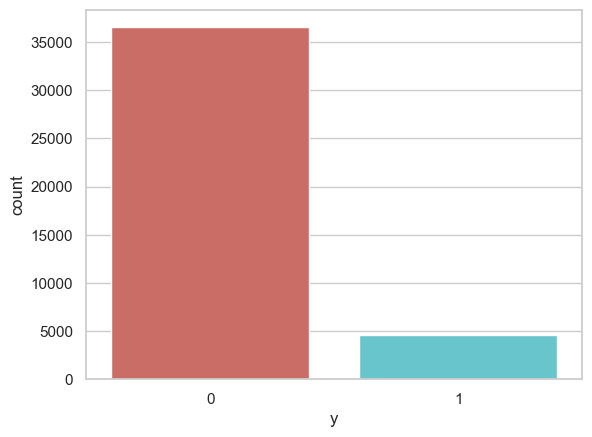

<Figure size 640x480 with 0 Axes>

In [41]:
sns.countplot(x='y', data=data, hue='y', palette='hls', legend=False)
plt.show()
plt.savefig('count_plot')

In [42]:
data['y'].value_counts(normalize='index')

y
0    0.887346
1    0.112654
Name: proportion, dtype: float64

In [43]:
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,44,blue-collar,married,Basic,unknown,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,...,3,6,2,success,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,services,married,high.school,no,no,no,cellular,apr,fri,...,2,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,retired,married,Basic,no,yes,no,cellular,aug,fri,...,1,3,1,success,-2.9,92.201,-31.4,0.869,5076.2,1


In [44]:
data.groupby('y').mean(numeric_only=True)

,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed
y,,,,,,,,,,
0,39.911185,220.844807,2.633085,984.113878,0.132374,0.248875,93.603757,-40.593097,3.811491,5176.166600
1,40.913147,553.191164,2.051724,792.035560,0.492672,-1.233448,93.354386,-39.789784,2.123135,5095.115991


In [45]:
data.groupby('job').mean(numeric_only=True)

,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
job,,,,,,,,,,,
admin.,38.187296,254.312128,2.623489,954.319229,0.189023,0.015563,93.534054,-40.245433,3.550274,5164.125350,0.129726
blue-collar,39.555760,264.542360,2.558461,985.160363,0.122542,0.248995,93.656656,-41.375816,3.771996,5175.615150,0.068943
entrepreneur,41.723214,263.267857,2.535714,981.267170,0.138736,0.158723,93.605372,-41.283654,3.791120,5176.313530,0.085165
housemaid,45.500000,250.454717,2.639623,960.579245,0.137736,0.433396,93.676576,-39.495283,4.009645,5179.529623,0.100000
management,42.362859,257.058140,2.476060,962.647059,0.185021,-0.012688,93.522755,-40.489466,3.611316,5166.650513,0.112175
retired,62.027326,273.712209,2.476744,897.936047,0.327326,-0.698314,93.430786,-38.573081,2.770066,5122.262151,0.252326
self-employed,39.949331,264.142153,2.660802,976.621393,0.143561,0.094159,93.559982,-40.488107,3.689376,5170.674384,0.104856
services,37.926430,258.398085,2.587805,979.974049,0.154951,0.175359,93.634659,-41.290048,3.699187,5171.600126,0.081381
student,25.894857,283.683429,2.104000,840.217143,0.524571,-1.408000,93.331613,-40.187543,1.884224,5085.939086,0.314286


In [46]:
data.groupby('marital').mean(numeric_only=True)

,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
marital,,,,,,,,,,,
divorced,44.899393,253.790330,2.61340,968.639853,0.168690,0.163985,93.606563,-40.707069,3.715603,5170.878643,0.103209
married,42.307165,257.438623,2.57281,967.247673,0.155608,0.183625,93.597367,-40.270659,3.745832,5171.848772,0.101573
single,33.158714,261.524378,2.53380,949.909578,0.211359,-0.167989,93.517300,-40.918698,3.317447,5155.199265,0.140041
unknown,40.275000,312.725000,3.18750,937.100000,0.275000,-0.221250,93.471250,-40.820000,3.313038,5157.393750,0.150000


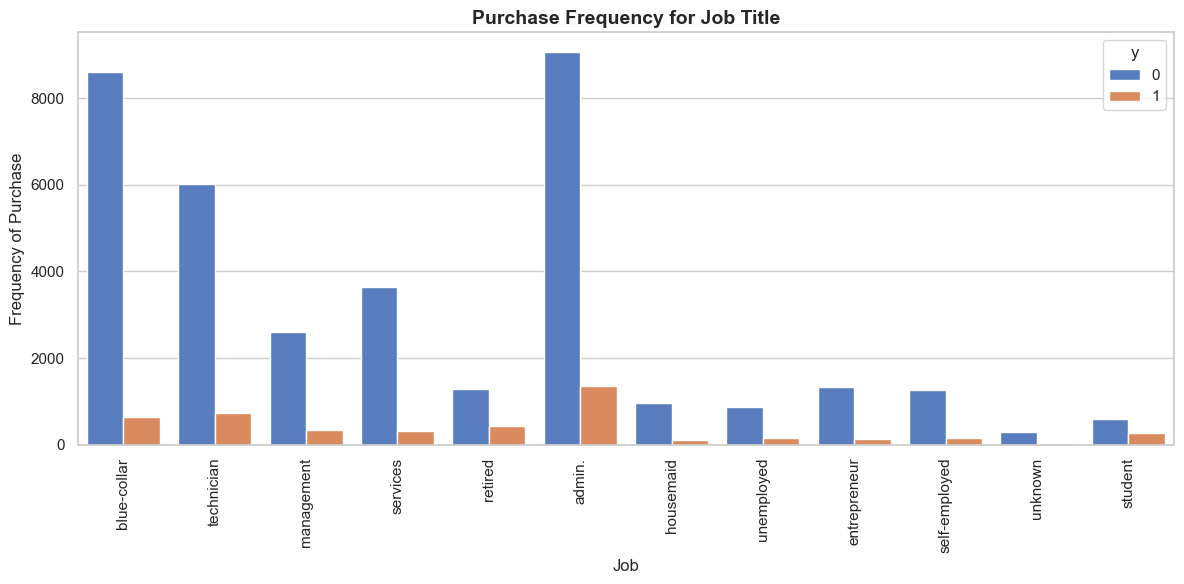

In [47]:
plt.figure(figsize=(12, 6))
sns.countplot(x='job', hue='y', data=data, palette='muted')
plt.title('Purchase Frequency for Job Title', fontsize=14, fontweight='bold')
plt.xlabel('Job')
plt.ylabel('Frequency of Purchase')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

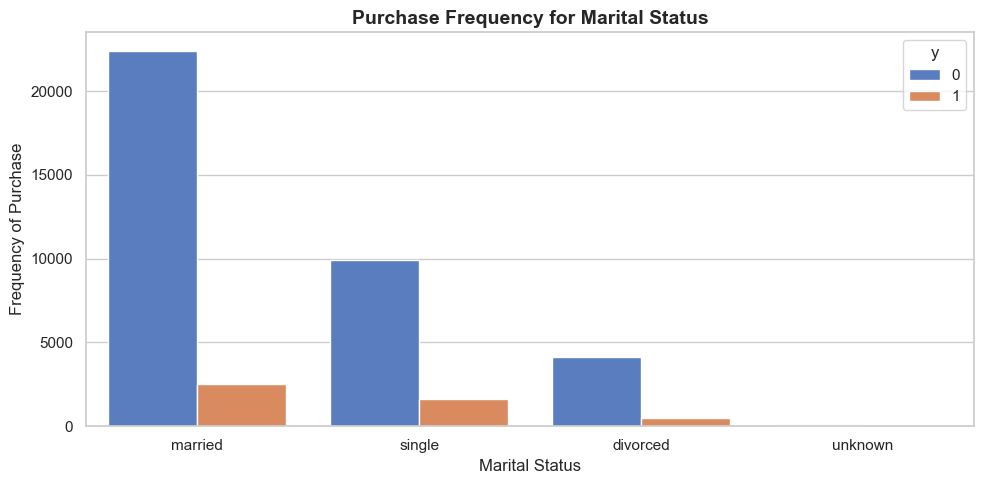

In [48]:
plt.figure(figsize=(10, 5))
# Create the side-by-side bar chart for marital status
sns.countplot(x='marital', hue='y', data=data, palette='muted')

plt.title('Purchase Frequency for Marital Status', fontsize=14, fontweight='bold')
plt.xlabel('Marital Status')
plt.ylabel('Frequency of Purchase')
plt.tight_layout()
plt.show()

In [49]:
data.shape

(41188, 21)

In [50]:
data = pd.get_dummies(data)
data.shape

(41188, 62)

In [51]:
data.head()


,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,...,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success
0,44,210,1,999,0,1.4,93.444,-36.1,4.963,5228.1,...,False,False,False,False,True,False,False,False,True,False
1,53,138,1,999,0,-0.1,93.200,-42.0,4.021,5195.8,...,False,False,True,False,False,False,False,False,True,False
2,28,339,3,6,2,-1.7,94.055,-39.8,0.729,4991.6,...,False,False,False,False,True,False,False,False,False,True
3,39,185,2,999,0,-1.8,93.075,-47.1,1.405,5099.1,...,False,False,True,False,False,False,False,False,True,False
4,55,137,1,3,1,-2.9,92.201,-31.4,0.869,5076.2,...,False,False,True,False,False,False,False,False,False,True


In [52]:
data = pd.get_dummies(data).astype(int)

In [53]:
print(data.columns.tolist())



['age', 'duration', 'campaign', 'pdays', 'previous', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'y', 'job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown', 'marital_divorced', 'marital_married', 'marital_single', 'marital_unknown', 'education_Basic', 'education_high.school', 'education_illiterate', 'education_professional.course', 'education_university.degree', 'education_unknown', 'default_no', 'default_unknown', 'default_yes', 'housing_no', 'housing_unknown', 'housing_yes', 'loan_no', 'loan_unknown', 'loan_yes', 'contact_cellular', 'contact_telephone', 'month_apr', 'month_aug', 'month_dec', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'day_of_week_fri', 'day_of_week_mon', 'day_of_week_thu', 'day_of_week_tue', 'day_of_week_wed', 'poutcome_failure', 'poutco

In [54]:
data.head()

,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,...,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success
0,44,210,1,999,0,1,93,-36,4,5228,...,0,0,0,0,1,0,0,0,1,0
1,53,138,1,999,0,0,93,-42,4,5195,...,0,0,1,0,0,0,0,0,1,0
2,28,339,3,6,2,-1,94,-39,0,4991,...,0,0,0,0,1,0,0,0,0,1
3,39,185,2,999,0,-1,93,-47,1,5099,...,0,0,1,0,0,0,0,0,1,0
4,55,137,1,3,1,-2,92,-31,0,5076,...,0,0,1,0,0,0,0,0,0,1


In [55]:
data = data.astype(int)


In [56]:
data.head()

,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,...,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success
0,44,210,1,999,0,1,93,-36,4,5228,...,0,0,0,0,1,0,0,0,1,0
1,53,138,1,999,0,0,93,-42,4,5195,...,0,0,1,0,0,0,0,0,1,0
2,28,339,3,6,2,-1,94,-39,0,4991,...,0,0,0,0,1,0,0,0,0,1
3,39,185,2,999,0,-1,93,-47,1,5099,...,0,0,1,0,0,0,0,0,1,0
4,55,137,1,3,1,-2,92,-31,0,5076,...,0,0,1,0,0,0,0,0,0,1


In [57]:
data.dtypes

age                     int64
duration                int64
campaign                int64
pdays                   int64
previous                int64
                        ...  
day_of_week_tue         int64
day_of_week_wed         int64
poutcome_failure        int64
poutcome_nonexistent    int64
poutcome_success        int64
Length: 62, dtype: object

In [58]:
x = data.drop('y', axis=1)
y = data['y']

In [59]:
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.7, test_size=0.3, random_state=100)

In [60]:
to_keep = data.columns.values.tolist()

In [61]:
data_final =data[to_keep]
data_final.columns.values

array(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp_var_rate',
       'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'y',
       'job_admin.', 'job_blue-collar', 'job_entrepreneur',
       'job_housemaid', 'job_management', 'job_retired',
       'job_self-employed', 'job_services', 'job_student',
       'job_technician', 'job_unemployed', 'job_unknown',
       'marital_divorced', 'marital_married', 'marital_single',
       'marital_unknown', 'education_Basic', 'education_high.school',
       'education_illiterate', 'education_professional.course',
       'education_university.degree', 'education_unknown', 'default_no',
       'default_unknown', 'default_yes', 'housing_no', 'housing_unknown',
       'housing_yes', 'loan_no', 'loan_unknown', 'loan_yes',
       'contact_cellular', 'contact_telephone', 'month_apr', 'month_aug',
       'month_dec', 'month_jul', 'month_jun', 'month_mar', 'month_may',
       'month_nov', 'month_oct', 'month_sep', 'day_of_week_fri',

In [62]:
print (data_final)

       age  duration  campaign  pdays  previous  emp_var_rate  cons_price_idx  \
0       44       210         1    999         0             1              93   
1       53       138         1    999         0             0              93   
2       28       339         3      6         2            -1              94   
3       39       185         2    999         0            -1              93   
4       55       137         1      3         1            -2              92   
...    ...       ...       ...    ...       ...           ...             ...   
41183   59       222         1    999         0             1              94   
41184   31       196         2    999         0             1              93   
41185   42        62         3    999         0             1              93   
41186   48       200         2    999         0            -3              92   
41187   25       112         4    999         0             1              93   

       cons_conf_idx  eurib

In [63]:
print (data_final.columns.values)

['age' 'duration' 'campaign' 'pdays' 'previous' 'emp_var_rate'
 'cons_price_idx' 'cons_conf_idx' 'euribor3m' 'nr_employed' 'y'
 'job_admin.' 'job_blue-collar' 'job_entrepreneur' 'job_housemaid'
 'job_management' 'job_retired' 'job_self-employed' 'job_services'
 'job_student' 'job_technician' 'job_unemployed' 'job_unknown'
 'marital_divorced' 'marital_married' 'marital_single' 'marital_unknown'
 'education_Basic' 'education_high.school' 'education_illiterate'
 'education_professional.course' 'education_university.degree'
 'education_unknown' 'default_no' 'default_unknown' 'default_yes'
 'housing_no' 'housing_unknown' 'housing_yes' 'loan_no' 'loan_unknown'
 'loan_yes' 'contact_cellular' 'contact_telephone' 'month_apr' 'month_aug'
 'month_dec' 'month_jul' 'month_jun' 'month_mar' 'month_may' 'month_nov'
 'month_oct' 'month_sep' 'day_of_week_fri' 'day_of_week_mon'
 'day_of_week_thu' 'day_of_week_tue' 'day_of_week_wed' 'poutcome_failure'
 'poutcome_nonexistent' 'poutcome_success']


In [64]:
x = data_final.loc[:, data_final.columns != 'y']
y = data_final.loc[:, data_final.columns == 'y']
from imblearn.over_sampling import SMOTE
os = SMOTE(random_state=0)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)
columns = x_train.columns
os_data_x,os_data_y=os.fit_resample(x_train, y_train)
os_data_x =pd.DataFrame(data=os_data_x,columns=columns)                        
os_data_y= pd.DataFrame(data=os_data_y,columns=['y'])
#we can check the numbers of our data
print("lenght of oversampled data is",len(os_data_x))
print("number of no subscriptions in oversampled data",len(os_data_y['y']==0))
print("number of subscriptions in oversampled data",len(os_data_y['y']==1))
print("proportion of no subsciptions in oversampled data is",len(os_data_y['y']==0)/len(os_data_x))
print("proportion of subsciptions in oversampled data is",len(os_data_y['y']==1)/len(os_data_x))

lenght of oversampled data is 51134
number of no subscriptions in oversampled data 51134
number of subscriptions in oversampled data 51134
proportion of no subsciptions in oversampled data is 1.0
proportion of subsciptions in oversampled data is 1.0


In [65]:
# 1. Separate variable lists
data_final_vars = data_final.columns.values.tolist()
y = ['y']
X = [i for i in data_final_vars if i not in y]

# 2. Import tools for feature selection
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# 3. Set up and run Recursive Feature Elimination (RFE)
logreg = LogisticRegression(solver='liblinear')
rfe = RFE(logreg, n_features_to_select=20)  # Selects the top 20 best features
rfe = rfe.fit(os_data_x, os_data_y.values.ravel())  # Matches your lowercase 'os_data_x'

# 4. View results
print(rfe.support_)
print(rfe.ranking_)

[False False False False False False False False False False False  True
  True  True  True False  True  True False  True False False False False
 False False  True  True False  True  True  True False False False  True
  True  True False False False False False False False False False False
 False False False False False  True  True  True  True  True False False
 False]
[42 36 35 41 34 32 33 39 29 38  3  1  1  1  1  5  1  1  6  1  4  2  9 10
 11 12  1  1 18  1  1  1 15 14 40  1  1  1 17 13 16 31 30 24 21 25 22 23
 28 19 20 26 27  1  1  1  1  1  8  7 37]


In [66]:
import statsmodels.api as sm

# 1. Automatically fetch the 20 column names your RFE tool chose
selected_cols = columns[rfe.support_].tolist()

# 2. Filter your balanced, oversampled datasets using those 20 columns
X_selected = os_data_x[selected_cols]
y_balanced = os_data_y['y']

# 3. Fit the model using Capital 'L' Logit
logit_model = sm.Logit(y_balanced, X_selected)
result = logit_model.fit(maxiter=200)  # <-- Fixed typo from logt_model to logit_model

# 4. Print the complete statistical report
print(result.summary2())

Optimization terminated successfully.
         Current function value: 0.541413
         Iterations 6
                                Results: Logit
Model:                   Logit                Method:               MLE       
Dependent Variable:      y                    Pseudo R-squared:     0.219     
Date:                    2026-08-16 22:25     AIC:                  55409.2142
No. Observations:        51134                BIC:                  55586.0583
Df Model:                19                   Log-Likelihood:       -27685.   
Df Residuals:            51114                LL-Null:              -35443.   
Converged:               1.0000               LLR p-value:          0.0000    
No. Iterations:          6.0000               Scale:                1.0000    
------------------------------------------------------------------------------
                               Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
-------------------------------------------------------------

In [67]:
# 1. Force the model to use the exact columns from the video
cols = [
    'duration', 'campaign', 'pdays', 'emp_var_rate', 'cons_price_idx', 
    'cons_conf_idx', 'euribor3m', 'month_apr', 'month_aug', 'month_dec', 
    'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 
    'month_oct', 'poutcome_failure', 'poutcome_success'
]

# 2. Extract these specific columns from your data
X_final = os_data_x[cols]
y_final = os_data_y['y']

# 3. Re-run the logit model with these columns
logit_model = sm.Logit(y_final, X_final)
result = logit_model.fit(maxiter=200)
print(result.summary2())


Optimization terminated successfully.
         Current function value: 0.254093
         Iterations 9
                         Results: Logit
Model:              Logit            Method:           MLE       
Dependent Variable: y                Pseudo R-squared: 0.633     
Date:               2026-08-16 22:25 AIC:              26021.5791
No. Observations:   51134            BIC:              26180.7388
Df Model:           17               Log-Likelihood:   -12993.   
Df Residuals:       51116            LL-Null:          -35443.   
Converged:          1.0000           LLR p-value:      0.0000    
No. Iterations:     9.0000           Scale:            1.0000    
-----------------------------------------------------------------
                  Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
-----------------------------------------------------------------
duration          0.0064   0.0001  83.7951 0.0000  0.0062  0.0065
campaign         -0.1678   0.0109 -15.4026 0.0000 -0.1891 -0.1464


In [68]:
cols = ['duration', 'campaign', 'pdays', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m']

In [69]:
x = data[cols]

In [70]:
# 1. Define the specific features chosen in the video step
cols = ['duration', 'campaign', 'pdays', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m']

# 2. Correctly rebuild x and y from your dataset
x = data_final[cols]
y = data_final['y']

# 3. Now run the train_test_split (this will work perfectly now!)
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.7, test_size=0.3, random_state=100)


In [71]:
# Pass y_train first, then x_train
logit_model = sm.Logit(y_train, x_train)

# Fit the model and print the summary
result = logit_model.fit(maxiter=200)
print(result.summary2())

Optimization terminated successfully.
         Current function value: 0.220812
         Iterations 8
                         Results: Logit
Model:              Logit            Method:           MLE       
Dependent Variable: y                Pseudo R-squared: 0.368     
Date:               2026-08-16 22:25 AIC:              12746.4866
No. Observations:   28831            BIC:              12804.3711
Df Model:           6                Log-Likelihood:   -6366.2   
Df Residuals:       28824            LL-Null:          -10069.   
Converged:          1.0000           LLR p-value:      0.0000    
No. Iterations:     8.0000           Scale:            1.0000    
-----------------------------------------------------------------
                  Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
-----------------------------------------------------------------
duration          0.0045   0.0001  52.9869 0.0000  0.0044  0.0047
campaign         -0.0610   0.0141  -4.3399 0.0000 -0.0886 -0.0335


In [73]:
# Use 'result' instead of 'logit_model'
y_pred = result.predict(x_test)

In [74]:
y_pred

33148    0.017031
27585    0.013543
15722    0.017153
40349    0.744929
2576     0.020562
           ...   
35346    0.138291
17896    0.116032
33711    0.008823
39853    0.012041
40806    0.085280
Length: 12357, dtype: float64

In [76]:
func = lambda x: 0 if x < 0.5 else 1
y_pred2 = y_pred.apply(func)

In [77]:
y_pred2

33148    0
27585    0
15722    0
40349    1
2576     0
        ..
35346    0
17896    0
33711    0
39853    0
40806    0
Length: 12357, dtype: int64

In [79]:
import sklearn.metrics as skm

In [80]:
skm.confusion_matrix(y_test, y_pred2)

array([[10665,   261],
       [  898,   533]])

In [86]:
func = lambda x: 0 if x <0.25 else 1
y_pred2 = y_pred.apply(func)
tn, fp, fn, tp = skm.confusion_matrix(y_test, y_pred2).ravel()
tpr = tp / (fn + tp)
fpr = fp / (fp + tn)
print(tpr,fpr)

0.6261355695317959 0.06397583745194947


In [87]:
fpr, tpr, threshold, = skm.roc_curve(y_test, y_pred)

In [88]:
fpr

array([0.00000000e+00, 9.15248032e-05, 9.15248032e-05, ...,
       9.95240710e-01, 9.95423760e-01, 1.00000000e+00])

In [89]:
tpr

array([0.        , 0.        , 0.00139762, ..., 1.        , 1.        ,
       1.        ])

In [90]:
threshold

array([           inf, 9.99999669e-01, 9.99990018e-01, ...,
       2.85165454e-03, 2.78941227e-03, 5.90248933e-04])

In [91]:
auc_score = skm.auc(fpr, tpr)
auc_score

np.float64(0.9209376322744469)

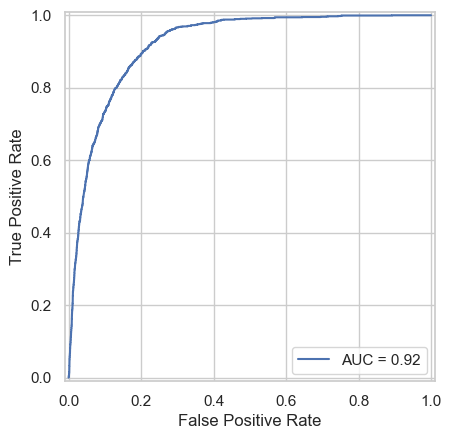

In [92]:
skm.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc_score).plot()